# 全臺偏遠受益型門市的實際路線:把東北角的「順路」驗證擴大到三個物流中心

**為什麼做這份:** `2_a_group_rebuild.ipynb` 第 1、3 節只看了瑞芳物流中心的東北角門市,發現全家**沒有專程配送**,每停一家東北角門市只多跑 3.8 km。`3_remote_scan.ipynb` 接著找出全臺 717 家偏遠受益型門市,但放大估算時用的每店效益仍然只來自東北角一個案例。這份 notebook 用三個物流中心(瑞芳、林口、高雄)的配送計畫,回答:

1. **配送計畫裡有哪些偏遠受益型門市?** 一天送幾次、由哪些班次送?
2. **這些門市是專程送,還是順路送?** 和東北角一樣排在幹線的頭尾,還是有整趟只為了幾家偏遠店出車?
3. **每家偏遠門市實際多跑幾公里(邊際里程)?** 和同趟的一般門市、東北角的 3.8 km 相比如何?
4. **用實測數字重算 `3_remote_scan` 的放大估算,結論會不會變?**

**資料:**
- 配送計畫:瑞芳 `delivery_plan/monthly/`(2024-01 ~ 2025-03)、林口與高雄 `delivery_plan_other_depots/`(2024-01 ~ 2025-12 / 2026-10)。三者都只有**全家**。
- 偏遠受益型門市:沿用 `3_remote_scan.ipynb` 第 2 節的條件(`d5 ≥ 5 km` 且 2 km 內有他牌),OSM 快取 `poc/cache/osm_convenience_tw.json`。
- 門市座標:門市主檔(只有北北基)、OSM 全家門市的 `branch` 店名與電話;道路距離取自 OSRM,快取於 `poc/cache/osrm_remote_routes.json`。

In [1]:
import glob, json, math, os, re, time, urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "poc" else os.getcwd()
P = lambda *a: os.path.join(ROOT, *a)
UA = {"User-Agent": "course-research/1.0"}
plt.rcParams.update({"font.family": "Microsoft JhengHei", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
BRANDS = ["7-Eleven", "全家", "OK", "萊爾富"]
DCS = ["瑞芳", "林口", "高雄"]
DCOL = {"瑞芳": "#2a78d6", "林口": "#1baf7a", "高雄": "#eb6834"}
# 各物流中心可能服務的縣市(只用來限制店名比對的範圍,避免同名門市跨縣市配錯)
CTY = {"瑞芳": ["新北市", "臺北市", "基隆市", "宜蘭縣"], "林口": ["新北市", "臺北市", "桃園市", "基隆市"],
       "高雄": ["高雄市", "屏東縣", "臺南市", "嘉義縣", "嘉義市", "臺東縣"]}
xy = lambda la, lo: np.c_[np.asarray(lo, float) * 101.0 * math.cos(math.radians(23.7)), np.asarray(la, float) * 111.0]   # 近似 km 座標

## 1. 偏遠受益型門市(沿用 `3_remote_scan` 的條件)

和 `3_remote_scan.ipynb` 第 1–2 節相同:OSM 四大品牌門市,`d5` = 離第 5 近的同品牌門市,`d_other` = 離最近的他牌門市(直線 km),`d5 ≥ 5` 且 `d_other ≤ 2` 為偏遠受益型。

In [2]:
osm = json.load(open(P("poc", "cache", "osm_convenience_tw.json"), encoding="utf-8"))
PAT = {"7-Eleven": r"7[\s\-‐‑]?eleven|7[\s\-]?11|統一超商|セブン", "全家": r"全家|family\s?mart",
       "萊爾富": r"萊爾富|hi[\s\-]?life", "OK": r"^ok\b|ok\s?mart|ok便利|ok超商|ok‧|來來超商"}

def brand_of(t):
    s = " | ".join(str(t.get(k, "")) for k in ["brand", "brand:zh", "brand:en", "name", "name:zh", "name:en", "operator"]).lower()
    for b in ["7-Eleven", "全家", "萊爾富"]:
        if re.search(PAT[b], s):
            return b
    for k in ["brand", "brand:en", "name", "name:en", "name:zh"]:
        if re.search(PAT["OK"], str(t.get(k, "")).lower()):
            return "OK"
    return None

rows = []
for e in osm:
    lat, lon = (e["lat"], e["lon"]) if e["type"] == "node" else (e["center"]["lat"], e["center"]["lon"])
    t = e.get("tags", {})
    rows.append({"osm_id": f"{e['type']}/{e['id']}", "lat": lat, "lon": lon, "name": t.get("name", ""), "branch": t.get("branch", ""),
                 "phone": t.get("phone", "") or t.get("contact:phone", ""), "brand": brand_of(t)})
TOWN = gpd.read_file(P("鄉(鎮、市、區)界線1140318", "TOWN_MOI_1140318.shp"))
TOWN["COUNTYNAME"] = TOWN["COUNTYNAME"].str.replace("台", "臺")
st = pd.DataFrame(rows).drop_duplicates("osm_id")
g = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st["lon"], st["lat"]), crs=TOWN.crs)
g = gpd.sjoin(g, TOWN[["COUNTYNAME", "TOWNNAME", "geometry"]], how="inner", predicate="within").drop(columns="index_right")
s4 = pd.DataFrame(g[g["brand"].notna()].drop(columns="geometry")).reset_index(drop=True)
sxy = xy(s4["lat"], s4["lon"])
for b in BRANDS:
    m = (s4["brand"] == b).values
    s4.loc[m, "d5"] = cKDTree(sxy[m]).query(sxy[m], k=6)[0][:, 5]
    s4.loc[m, "d_other"] = cKDTree(sxy[~m]).query(sxy[m], k=1)[0]
s4["偏遠受益型"] = (s4["d5"] >= 5) & (s4["d_other"] <= 2)
fm = s4[s4["brand"] == "全家"].copy()
print(f"四大品牌偏遠受益型 {int(s4['偏遠受益型'].sum())} 家(與 3_remote_scan 相同);其中全家 {int(fm['偏遠受益型'].sum())} 家")

四大品牌偏遠受益型 717 家(與 3_remote_scan 相同);其中全家 215 家


## 2. 三個物流中心的配送計畫

把三份資料整理成同一格式,一列 = 一趟中的一個門市停靠。**一趟** = (物流中心, 日期, 任務, 路線, 車號)。停靠順序用實際到店時間;缺時間的趟次改用站序(瑞芳 `Route_seq` 後兩碼、林口與高雄 `Order_Index`)。

In [3]:
mp = pd.concat([pd.read_csv(f, dtype=str, encoding="utf-8-sig") for f in sorted(glob.glob(P("delivery_plan", "monthly", "*.csv")))])
parts = [pd.DataFrame({"dc": "瑞芳", "date": pd.to_datetime(mp["Delivery_Dt"]), "task": mp["TaskType_id"].str.zfill(2),
                       "route": mp["Route_seq"].str[:2], "car": mp["Car_licence"].fillna("NA"), "store_id": mp["Store_id"],
                       "store": mp["Store_Name"], "seq": pd.to_numeric(mp["Route_seq"].str[2:], errors="coerce"),
                       "act": pd.to_datetime(mp["Ac_Arrive_dt_02"], errors="coerce"), "tel": np.nan})]
raw = {}
for d, nm in [("linkou_LC", "林口"), ("kaohsiung_YT", "高雄")]:
    x = pd.read_csv(P("delivery_plan_other_depots", "delivery_plan_other_depots", d, "all_delivery.csv"), dtype=str)
    x["date"] = pd.to_datetime(x["Delivery_date"], format="%m/%d/%Y %I:%M:%S %p")
    raw[nm] = x
    parts.append(pd.DataFrame({"dc": nm, "date": x["date"], "task": x["TaskType_id"].str.zfill(2), "route": x["Route_id"],
                               "car": x["Car_id"].fillna("NA"), "store_id": x["Store_id"], "store": x["Store_Name"],
                               "seq": pd.to_numeric(x["Order_Index"], errors="coerce"),
                               "act": pd.to_datetime(x["Ac_Arrive_dt_01"], errors="coerce"), "tel": x["tel"]}))
dp = pd.concat(parts, ignore_index=True)
dp = dp[dp["store_id"].str.startswith("1001", na=False)].copy()
dp["trip"] = dp["dc"] + "|" + dp["date"].dt.strftime("%Y-%m-%d") + "|" + dp["task"] + "|" + dp["route"] + "|" + dp["car"]
dp = dp.drop_duplicates(["trip", "store_id"])
pd.DataFrame({"期間": dp.groupby("dc")["date"].agg(lambda s: f"{s.min():%Y-%m} ~ {s.max():%Y-%m}"),
              "天數": dp.groupby("dc")["date"].nunique(), "趟數": dp.groupby("dc")["trip"].nunique(),
              "門市停靠": dp.groupby("dc").size(), "門市數": dp.groupby("dc")["store_id"].nunique()}).reindex(DCS)

,期間,天數,趟數,門市停靠,門市數
dc,,,,,
瑞芳,2024-01 ~ 2025-03,456,19286,310746,806
林口,2024-01 ~ 2026-04,732,5651,123855,894
高雄,2024-01 ~ 2026-10,1023,18269,266669,1221


### 2.1 門市定位

配送計畫只有店名,沒有座標。依序用五種方法找座標,前面的方法找到就不再往下:

1. **門市主檔**:以店名對應(主檔只有臺北、新北、基隆,所以只對瑞芳、林口有用)。
2. **OSM 店名**:OSM 全家門市的 `branch` 標籤(例如「燕巢深水店」),限該物流中心服務的縣市、店名唯一者。
3. **OSM 電話**:配送計畫的門市電話(只有林口、高雄有)對 OSM 的 `phone`。
4. **OSM 店名(去地名)**:配送計畫的店名多加了地名前綴(「高雄富國」),去掉前 2–3 字後再比一次,同樣限縣市、唯一。
5. **鄉鎮估計**:店名開頭是鄉鎮名(「麻豆興民」→ 麻豆區)時,取該鄉鎮內**還沒被配對**的 OSM 全家門市;只有一家就用它,有多家就取平均位置,沒有就用鄉鎮的代表點。這一類只用來補路線上的鄰近門市,誤差約為鄉鎮尺度。

In [4]:
norm = lambda x: re.sub(r"^(全家便利商店|全家|FamilyMart)\s*|店$", "", str(x).strip())
fm["bkey"] = fm["branch"].map(norm)
fm["ph"] = fm["phone"].str.replace(r"\D", "", regex=True).str.replace(r"^886", "0", regex=True)
sm = pd.read_csv(P("store_master", "store_master.csv"), encoding="utf-8-sig")
sm["key"] = sm["name"].map(norm)

u = dp.groupby(["dc", "store_id", "store"]).agg(停靠次數=("trip", "size"), tel=("tel", "first")).reset_index()
u["key"] = u["store"].map(norm)
u["ph"] = u["tel"].fillna("").str.replace(r"\D", "", regex=True)
u = u.merge(sm.drop_duplicates("key")[["key", "lat", "lng"]].rename(columns={"lng": "lon"}), on="key", how="left")
u["src"] = np.where(u["lat"].notna(), "門市主檔", None)
u["cand"] = None   # 對應的 OSM 全家門市(可能多家)

def fill(mask, lat, lon, src, cand):
    idx = u.index[mask]
    u.loc[idx, "lat"], u.loc[idx, "lon"], u.loc[idx, "src"] = lat, lon, src
    u.loc[idx, "cand"] = pd.Series(cand, index=idx)

for dc, cs in CTY.items():
    f_ = fm[fm["COUNTYNAME"].isin(cs)]
    bk = f_[f_["bkey"] != ""]; bk = bk[bk["bkey"].map(bk["bkey"].value_counts()) == 1].set_index("bkey")
    pk = f_[f_["ph"].str.len() >= 8]; pk = pk[pk["ph"].map(pk["ph"].value_counts()) == 1].set_index("ph")
    m = (u["dc"] == dc) & u["lat"].isna() & u["key"].isin(bk.index)
    r = bk.loc[u.loc[m, "key"]]; fill(m, r["lat"].values, r["lon"].values, "OSM 店名", [[o] for o in r["osm_id"]])
    m = (u["dc"] == dc) & u["lat"].isna() & u["ph"].isin(pk.index)
    r = pk.loc[u.loc[m, "ph"]]; fill(m, r["lat"].values, r["lon"].values, "OSM 電話", [[o] for o in r["osm_id"]])
    k2 = u["key"].map(lambda k: next((kk for kk in [k[2:], k[3:]] if len(k) >= 4 and kk in bk.index), None))
    m = (u["dc"] == dc) & u["lat"].isna() & k2.notna()
    r = bk.loc[k2[m]]; fill(m, r["lat"].values, r["lon"].values, "OSM 店名(去地名)", [[o] for o in r["osm_id"]])

# 主檔座標也對到最近的 OSM 全家門市(≤ 300 m 視為同一家)
T_fm = cKDTree(xy(fm["lat"], fm["lon"]))
m = (u["src"] == "門市主檔")
d_, j_ = T_fm.query(xy(u.loc[m, "lat"], u.loc[m, "lon"]))
u.loc[m, "cand"] = pd.Series([[fm["osm_id"].iat[j]] if d <= 0.3 else [] for d, j in zip(d_, j_)], index=u.index[m])

used = set(o for c in u["cand"].dropna() for o in c)
TOWN["short"] = TOWN["TOWNNAME"].str.replace(r"[鄉鎮市區]$", "", regex=True)
for dc, cs in CTY.items():
    tw = TOWN[TOWN["COUNTYNAME"].isin(cs)]
    for i in u.index[(u["dc"] == dc) & u["lat"].isna()]:
        k = u.at[i, "key"]
        hit = tw[tw["short"].map(lambda s: len(s) >= 2 and k.startswith(s))]
        hit = hit[hit["short"].str.len() == hit["short"].str.len().max()]
        if len(hit) != 1:
            continue
        c, t = hit.iloc[0][["COUNTYNAME", "TOWNNAME"]]
        cand = fm[(fm["COUNTYNAME"] == c) & (fm["TOWNNAME"] == t) & ~fm["osm_id"].isin(used)]
        if len(cand):
            u.loc[i, ["lat", "lon"]] = [cand["lat"].mean(), cand["lon"].mean()]
            u.at[i, "src"] = "鄉鎮估計(唯一)" if len(cand) == 1 else "鄉鎮估計(平均)"
        else:
            pt = hit.iloc[0].geometry.representative_point()
            u.loc[i, ["lat", "lon"]] = [pt.y, pt.x]; u.at[i, "src"] = "鄉鎮估計(代表點)"
        u.at[i, "cand"] = cand["osm_id"].tolist()
u["src"] = u["src"].fillna("找不到")
u["精確"] = ~u["src"].str.startswith(("鄉鎮", "找不到"))

SRC = ["門市主檔", "OSM 店名", "OSM 電話", "OSM 店名(去地名)", "鄉鎮估計(唯一)", "鄉鎮估計(平均)", "鄉鎮估計(代表點)", "找不到"]
loc_tab = pd.crosstab(u["dc"], u["src"]).reindex(index=DCS, columns=SRC, fill_value=0)
w = u.groupby("dc")["停靠次數"].sum()
loc_tab["停靠次數加權:精確"] = ((u["停靠次數"] * u["精確"]).groupby(u["dc"]).sum() / w).map("{:.0%}".format)
loc_tab["停靠次數加權:有座標"] = ((u["停靠次數"] * (u["src"] != "找不到")).groupby(u["dc"]).sum() / w).map("{:.0%}".format)
loc_tab

src,門市主檔,OSM 店名,OSM 電話,OSM 店名(去地名),鄉鎮估計(唯一),鄉鎮估計(平均),鄉鎮估計(代表點),找不到,停靠次數加權:精確,停靠次數加權:有座標
dc,,,,,,,,,,
瑞芳,718,45,0,1,2,19,2,20,98%,98%
林口,792,42,1,2,3,37,0,19,95%,98%
高雄,0,498,13,11,40,134,48,477,41%,53%


**判讀:** 瑞芳、林口的門市幾乎都能從門市主檔定位(停靠次數加權約 95% 以上);高雄的門市不在主檔,只能靠 OSM,找不到的大多是「高雄○○店」「台南○○店」這類**市區門市**(店名沒有鄉鎮、OSM 也沒標店名)。偏遠門市在 OSM 的標註比較完整,所以對下面的分析影響較小;受影響的是「偏遠店前後一站」的座標,第 4 節會把這類趟次標出來。

### 2.2 物流中心位置

瑞芳、林口物流中心在門市主檔中有座標。高雄物流中心沒有,改用資料反推:每一趟從物流中心出發到第一站的實際時間,應該和兩點距離成正比,所以在地圖上找一個點,讓「到各趟第一站的直線距離」和「行駛時間」的相關最高。先用林口、瑞芳(已知位置)驗證方法。

In [5]:
DC_XY = {d: tuple(sm.loc[sm["name"] == f"{d}ＤＣ", ["lat", "lng"]].iloc[0]) for d in ["瑞芳", "林口"]}
locd = u.dropna(subset=["lat"]).set_index(["dc", "store_id"])[["lat", "lon"]]

def first_legs(nm):
    if nm == "瑞芳":
        x = mp.assign(t=pd.to_datetime(mp["Ac_Arrive_dt_02"], errors="coerce"), seq=pd.to_numeric(mp["Route_seq"].str[2:], errors="coerce"),
                      trip=mp["Delivery_Dt"] + mp["TaskType_id"] + mp["Route_seq"].str[:2] + mp["Car_licence"].fillna(""))
        dep = x[x["Store_id"] == "S3001888888"]; stp = x[x["Store_id"].str.startswith("1001", na=False)]
    else:
        x = raw[nm].assign(t=lambda d: pd.to_datetime(d["Ac_Arrive_dt_01"], errors="coerce"), seq=lambda d: pd.to_numeric(d["Order_Index"]),
                           trip=lambda d: d["Delivery_date"] + d["TaskType_id"] + d["Route_id"] + d["Car_id"].fillna(""))
        dep = x[x["seq"] == -1]; stp = x[x["last_dc"] == "0"]
    dep = dep.dropna(subset=["t"]).drop_duplicates("trip").set_index("trip")["t"]
    fst = stp.dropna(subset=["t"]).sort_values(["trip", "t"]).drop_duplicates("trip").set_index("trip")
    fst = fst.join(dep.rename("t0"), how="inner")
    fst["min"] = (fst["t"] - fst["t0"]).dt.total_seconds() / 60
    fst = fst.join(locd.loc[nm], on="Store_id", how="inner")
    return fst[(fst["min"] > 1) & (fst["min"] < 240)]

LAND = TOWN.geometry.simplify(0.005).unary_union

def locate_dc(fl, step=0.005, span=0.5):
    # 找「到第一站的直線距離」與「行駛分鐘」相關最高、且在陸地上的格點
    la0, lo0 = fl["lat"].median(), fl["lon"].median()
    LA, LO = np.meshgrid(np.arange(la0 - span, la0 + span, step), np.arange(lo0 - span, lo0 + span, step), indexing="ij")
    d = np.hypot((fl["lat"].values[None, None] - LA[..., None]) * 111, (fl["lon"].values[None, None] - LO[..., None]) * 102)
    tm = fl["min"].values
    r = ((d - d.mean(-1, keepdims=True)) * (tm - tm.mean())).mean(-1) / (d.std(-1) * tm.std())
    for i in np.argsort(-np.nan_to_num(r, nan=-1), axis=None):
        i = np.unravel_index(i, r.shape)
        if LAND.contains(Point(LO[i], LA[i])):
            return LA[i], LO[i], r[i]

from shapely.geometry import Point
rows, est = [], {}
for nm in DCS:
    fl = first_legs(nm)
    for cap in [240, 90, 60]:
        la, lo, r = locate_dc(fl[fl["min"] <= cap])
        est[(nm, cap)] = (la, lo)
        ref = DC_XY.get(nm, est[(nm, 240)])
        rows.append({"物流中心": nm, "第一段上限(分)": cap, "趟數": int((fl["min"] <= cap).sum()), "反推緯度": la, "反推經度": lo,
                     "相關係數": r, "與實際位置差(km)" if nm in DC_XY else "與上限 240 分的估計差(km)":
                     math.hypot((la - ref[0]) * 111, (lo - ref[1]) * 102)})
DC_XY["高雄"] = est[("高雄", 240)]
pd.DataFrame(rows).style.hide(axis="index").format(precision=3, na_rep="")

物流中心,第一段上限(分),趟數,反推緯度,反推經度,相關係數,與實際位置差(km),與上限 240 分的估計差(km)
瑞芳,240,7464,25.019,121.999,0.303,24.951,
瑞芳,90,6998,25.109,121.924,0.400,15.408,
瑞芳,60,6075,25.109,121.799,0.538,2.688,
林口,240,3297,25.115,121.379,0.182,4.077,
林口,90,2971,25.125,121.313,0.241,10.001,
林口,60,2281,25.095,121.340,0.345,6.323,
高雄,240,7015,22.807,120.298,0.214,,0.000
高雄,90,6076,22.812,120.303,0.370,,0.754
高雄,60,5149,22.817,120.311,0.521,,1.742


**判讀:** 這個方法**不太穩**:相關係數只有 0.2–0.5(出車後常先等候、休息,行駛時間雜訊大)。已知位置的兩個物流中心,誤差在 3–25 km 之間,而且隨「第一段上限」改變,只有限制在 60 分鐘內時兩者都在 7 km 內。高雄則不論怎麼設定,估計點都在**岡山、燕巢交界**一帶,彼此相差不到 2 km,也和全家 2018 年完工的岡山多溫層物流中心相符(食力 foodNEXT 報導),所以採用上限 240 分鐘的估計點。物流中心座標只影響「偏遠店排在一趟第一站或最後一站」的趟次,這部分的邊際里程可能有數公里的誤差。

## 3. 配送計畫裡的偏遠受益型門市

判定方式:精確定位的門市,若對得到 OSM 全家門市(≤ 300 m)就沿用 `3_remote_scan` 的判定;主檔座標但 OSM 沒有的門市,用它自己的座標算 `d5`、`d_other`;鄉鎮估計的門市只有在候選的 OSM 門市**全部**是偏遠受益型時才算。

In [6]:
flag = fm.set_index("osm_id")["偏遠受益型"]
oth_xy = xy(s4.loc[s4["brand"] != "全家", "lat"], s4.loc[s4["brand"] != "全家", "lon"])

def is_remote(r):
    if r["src"] == "找不到":
        return False
    if r["cand"]:
        return bool(flag.loc[r["cand"]].all())
    if r["src"] == "門市主檔":
        dd, _ = T_fm.query(xy([r["lat"]], [r["lon"]]), k=5)
        d_o, _ = cKDTree(oth_xy).query(xy([r["lat"]], [r["lon"]]))
        return bool(dd[0][4] >= 5 and d_o[0] <= 2)
    return False

u["偏遠受益型"] = u.apply(is_remote, axis=1)
dp = dp.merge(u[["dc", "store_id", "lat", "lon", "精確", "偏遠受益型"]], on=["dc", "store_id"], how="left")
dp["偏遠受益型"] = dp["偏遠受益型"].fillna(False).astype(bool)

ndays = dp.groupby("dc")["date"].nunique()
R = dp[dp["偏遠受益型"]]
rs = (R.groupby(["dc", "store_id"])
       .agg(門市=("store", "first"), 停靠次數=("trip", "size"), 有送的天數=("date", "nunique"),
            任務=("task", lambda s: "、".join(f"{k}×{v}" for k, v in s.value_counts().items())),
            路線數=("route", "nunique"), lat=("lat", "first"), lon=("lon", "first"))
       .reset_index())
rs["每個有送日幾次"] = rs["停靠次數"] / rs["有送的天數"]
rs["有送天數佔比"] = rs["有送的天數"] / rs["dc"].map(ndays)
rs = rs.merge(u[["dc", "store_id", "cand"]], on=["dc", "store_id"])
osm_r = fm[fm["偏遠受益型"]].set_index("osm_id")
tj = gpd.sjoin(gpd.GeoDataFrame(rs[["lat", "lon"]], geometry=gpd.points_from_xy(rs["lon"], rs["lat"]), crs=TOWN.crs),
               TOWN[["COUNTYNAME", "TOWNNAME", "geometry"]], how="left", predicate="within")
rs["縣市"], rs["鄉鎮"] = tj["COUNTYNAME"].values, tj["TOWNNAME"].values
rs["d5"] = rs["cand"].map(lambda c: osm_r.at[c[0], "d5"] if c and c[0] in osm_r.index else np.nan)
# 同一家店在不同期間用了不同門市代碼:以「物流中心 + 店名」合併
rs = (rs.groupby(["dc", "門市"]).agg(縣市=("縣市", "first"), 鄉鎮=("鄉鎮", "first"), d5=("d5", "first"), 停靠次數=("停靠次數", "sum"),
                                    有送的天數=("有送的天數", "sum"), 任務=("任務", "first"), 路線數=("路線數", "max"),
                                    lat=("lat", "first"), lon=("lon", "first"), cand=("cand", "first")).reset_index())
rs["每個有送日幾次"] = rs["停靠次數"] / rs["有送的天數"]
print("配送計畫中的偏遠受益型門市:", rs.groupby("dc").size().reindex(DCS).to_dict(), f"合計 {len(rs)} 家")
rs.sort_values(["dc", "縣市", "停靠次數"], ascending=[True, True, False])[
    ["dc", "縣市", "鄉鎮", "門市", "d5", "停靠次數", "有送的天數", "每個有送日幾次", "任務", "路線數"]].round(2).style.hide(axis="index").format(precision=1)

配送計畫中的偏遠受益型門市: {'瑞芳': 14, '林口': 3, '高雄': 50} 合計 67 家


dc,縣市,鄉鎮,門市,d5,停靠次數,有送的天數,每個有送日幾次,任務,路線數
林口,新北市,三芝區,三芝如意店,9.4,12,12,1.0,12×12,2
林口,新北市,石門區,石門粽香店,10.5,12,12,1.0,12×12,2
林口,新北市,三芝區,三芝吉祥店,9.4,11,11,1.0,12×5,1
瑞芳,宜蘭縣,頭城鎮,頭城梗枋店,11.3,1,1,1.0,05×1,1
瑞芳,新北市,坪林區,坪林順益店,11.4,669,456,1.5,05×456、12×213,2
瑞芳,新北市,平溪區,平溪平安店,7.7,221,221,1.0,12×221,1
瑞芳,新北市,金山區,金山金中店,8.7,89,85,1.1,05×66、03×13、04×7、12×2、A4×1,4
瑞芳,新北市,萬里區,萬里頂社店,6.9,87,83,1.1,05×66、03×13、04×5、12×2、A4×1,4
瑞芳,新北市,萬里區,野柳新港口店,5.3,87,83,1.1,03×10、05×8、12×1,4
瑞芳,新北市,金山區,金山中山店,8.9,87,83,1.1,05×66、03×13、04×5、12×2、A4×1,4


In [7]:
# 全臺 215 家偏遠受益型全家門市,有多少出現在這三個物流中心的資料裡
found = set(o for c in rs["cand"] for o in c)
cov = (fm[fm["偏遠受益型"]].assign(出現在配送計畫=lambda d: d["osm_id"].isin(found))
       .groupby("COUNTYNAME")["出現在配送計畫"].agg(["size", "sum"]).rename(columns={"size": "OSM 偏遠受益型全家", "sum": "出現在三場站"}))
cov = cov.sort_values("OSM 偏遠受益型全家", ascending=False)
print(f"OSM 偏遠受益型全家門市 {int(cov.iloc[:, 0].sum())} 家,出現在三個物流中心配送計畫中的 {int(cov.iloc[:, 1].sum())} 家")
cov.T

OSM 偏遠受益型全家門市 215 家,出現在三個物流中心配送計畫中的 62 家


COUNTYNAME,雲林縣,屏東縣,臺南市,嘉義縣,新北市,南投縣,花蓮縣,高雄市,臺東縣,苗栗縣,宜蘭縣,新竹縣,彰化縣,連江縣,臺中市,澎湖縣,金門縣,桃園市
OSM 偏遠受益型全家,23,23,20,18,16,15,14,14,13,13,11,7,7,5,5,4,4,3
出現在三場站,0,16,9,0,14,0,0,14,8,0,1,0,0,0,0,0,0,0


**判讀(第 3 節):**

- 三個物流中心的資料裡共有 **67 家**偏遠受益型全家門市:高雄 50 家(屏東 16、高雄市 16、臺南 10、臺東 8 家)、瑞芳 14 家(金山、萬里、烏來、坪林、新店山區、九份、金瓜石、平溪)、林口 3 家(三芝、石門)。
- 對回 OSM,全臺 215 家偏遠受益型全家門市中有 **62 家**出現在這三份資料裡。雲林、嘉義、南投、花蓮、苗栗、宜蘭等縣市**一家都沒有**,這些門市屬於其他物流中心的轄區,本 notebook 無法驗證。
- **配送頻次:** 有送的日子裡幾乎都是**一天一次**(中位數 1.02 次),只有坪林順益店一天約 1.5 次(晚班 05 與早班 12 都會送)。`3_remote_scan` 的「每日一輪」假設成立。
- **常態配送與零星配送要分開看:** 坪林、平溪、燕巢新民、阿蓮、新化那拔等店幾乎天天出現;臺東 8 家(含綠島)只在 2–3 天出現、都是任務 12,墾丁大街、頭城梗枋只出現 1 次,林口的三芝、石門只出現 11–12 天。這些可能是臨時支援或資料缺漏,不代表由該物流中心常態配送。金山、萬里一帶的門市只在 456 天中的 83 天出現,也和 `2_a_group_rebuild` 第 1 節觀察到的資料缺漏一致。

## 4. 含偏遠受益型門市的趟次:專程還是順路?

先不算距離,只看排班:一趟有幾家店、偏遠店佔幾家、排在趟次的哪一段。和 `2_a_group_rebuild` 第 1 節一樣,前 1/3 稱為前段、後 1/3 稱為後段。

In [8]:
def ordered(g):
    return g.sort_values(["act", "seq"]) if g["act"].notna().all() else g.sort_values("seq")

TR = dp[dp["trip"].isin(set(R["trip"]))].copy()
trips = {t: ordered(g).reset_index(drop=True) for t, g in TR.groupby("trip")}

def quality(g):
    # 偏遠店的前一站、後一站(連續的偏遠店視為一段)是否都有精確座標
    rem, n = g["偏遠受益型"].values, len(g)
    prec, has = g["精確"].fillna(False).values, g["lat"].notna().values
    q = "精確"
    for i in np.where(rem)[0]:
        if not prec[i]:
            return "缺座標"
        j = i - 1
        while j >= 0 and rem[j]: j -= 1
        k = i + 1
        while k < n and rem[k]: k += 1
        for nb in [j, k]:
            if 0 <= nb < n:
                if not has[nb]:
                    return "缺座標"
                if not prec[nb]:
                    q = "含鄉鎮估計"
    return q

rows = []
for t, g in trips.items():
    i = np.where(g["偏遠受益型"].values)[0]
    pos = i.mean() / max(len(g) - 1, 1)
    rows.append({"trip": t, "dc": g["dc"].iat[0], "任務": g["task"].iat[0], "路線": g["route"].iat[0], "停靠店數": len(g),
                 "偏遠店數": len(i), "位置": "前段" if pos < 1 / 3 else ("後段" if pos > 2 / 3 else "中段"), "座標品質": quality(g)})
TT = pd.DataFrame(rows)
TT["偏遠佔比"] = TT["偏遠店數"] / TT["停靠店數"]
TT["偏遠過半"] = TT["偏遠佔比"] >= 0.5
tab = TT.groupby(["dc", "任務"]).agg(趟數=("trip", "size"), 每趟店數中位數=("停靠店數", "median"), 偏遠店數中位數=("偏遠店數", "median"),
                                   偏遠過半的趟次=("偏遠過半", "mean"),
                                   前段=("位置", lambda s: (s == "前段").mean()), 中段=("位置", lambda s: (s == "中段").mean()),
                                   後段=("位置", lambda s: (s == "後段").mean()))
display(tab.reindex(DCS, level=0).style.format({"偏遠過半的趟次": "{:.0%}", "前段": "{:.0%}", "中段": "{:.0%}", "後段": "{:.0%}",
                                                 "每趟店數中位數": "{:.0f}", "偏遠店數中位數": "{:.0f}"}))
print("座標品質(趟數):")
pd.crosstab(TT["dc"], TT["座標品質"]).reindex(index=DCS, columns=["精確", "含鄉鎮估計", "缺座標"], fill_value=0)

座標品質(趟數):


座標品質,精確,含鄉鎮估計,缺座標
dc,,,
瑞芳,829,0,0
林口,13,0,0
高雄,487,825,551


**判讀(第 4 節):**

- **和東北角一樣,沒有專程趟次。** 含偏遠店的 2,700 多趟中,偏遠店過半的趟次只有 0–3%(瑞芳 A4、高雄 01 這類只有 1–2 趟的任務除外)。偏遠店一律和 6–24 家一般門市排在同一趟,每趟通常只有 1–4 家偏遠店。
- **排在哪一段因物流中心而異:**
  - **瑞芳**的偏遠店幾乎都排在**後段**(晚班 05 有 88%、早班 12 全部):坪林、烏來、平溪都是送完市區最後再繞過去,和平溪在 SE 路線的情形相同。
  - **高雄**的主力任務 04 多排在**前段、中段**:出岡山後先往阿蓮、燕巢、旗山或屏東方向送偏遠店,再進市區。
- 高雄有 551 趟(約 30%)因偏遠店的前後站沒有座標,第 6 節不採用;另有 825 趟用到鄉鎮估計的座標。

## 5. 道路距離(OSRM)

每個物流中心各建一個距離矩陣,點位 = 物流中心 + 含偏遠門市的趟次中所有有座標的門市。點數超過 OSRM 公開服務單次 100 點的上限,分批查詢後組合(與 `2_a_group_rebuild` 第 2 節相同作法),結果存在快取,重跑不必重新查詢。

**最短路徑修正:** OSRM 回傳的是**最快**路線的距離,不一定最短。例如石碇 → 平溪十分走快速道路 30.6 km,經過平溪平安店卻只要 19.4 km,拿掉平安店反而「變遠」,邊際里程變成負的。所以對矩陣做一次 Floyd–Warshall,讓「經過其他門市」的走法也算可行路線(`2_a_group_rebuild` 沒做這一步,東北角的數字可能因此略為低估)。

In [9]:
cache = P("poc", "cache", "osrm_remote_routes.json")
OC = json.load(open(cache, encoding="utf-8")) if os.path.exists(cache) else {}
NODE, DM = {}, {}
for nm in DCS:
    pts = TR[(TR["dc"] == nm) & TR["lat"].notna()].drop_duplicates("store_id")
    names = ["DC"] + pts["store_id"].tolist()
    coords = [DC_XY[nm][::-1]] + list(zip(pts["lon"], pts["lat"]))
    key = [f"{n}@{x:.5f},{y:.5f}" for n, (x, y) in zip(names, coords)]
    if nm in OC and OC[nm]["key"] == key:
        D = np.array(OC[nm]["D"], dtype=float)
    else:
        n, B = len(key), 45
        D = np.full((n, n), np.nan)
        blocks = [list(range(i, min(i + B, n))) for i in range(0, n, B)]
        for a in blocks:
            for b in blocks:
                ids = a + [j for j in b if j not in a]
                url = ("https://router.project-osrm.org/table/v1/driving/" + ";".join(f"{coords[i][0]:.6f},{coords[i][1]:.6f}" for i in ids)
                       + "?sources=" + ";".join(str(k) for k in range(len(a))) + "&destinations=" + ";".join(str(ids.index(j)) for j in b)
                       + "&annotations=distance")
                for tryn in range(5):
                    try:
                        r = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=180)); break
                    except Exception:
                        time.sleep(5 * (tryn + 1))
                assert r["code"] == "Ok", r.get("code")
                D[np.ix_(a, b)] = np.array(r["distances"], dtype=float)
                time.sleep(0.3)
        OC[nm] = {"key": key, "D": D.tolist()}
        json.dump(OC, open(cache, "w", encoding="utf-8"))
    NODE[nm] = {s: i for i, s in enumerate(names)}
    raw_km = D / 1000
    DM[nm] = raw_km.copy()
    for k in range(len(D)):   # Floyd–Warshall
        np.minimum(DM[nm], DM[nm][:, [k]] + DM[nm][[k], :], out=DM[nm])
    print(f"{nm}:{len(names)} 點;最短路徑修正後平均縮短 {np.nanmean(raw_km - DM[nm]):.2f} km,"
          f"{np.nanmean(raw_km - DM[nm] > 0.5):.0%} 的點對縮短超過 0.5 km")
# 道路 ÷ 直線(繞行係數),檢查距離矩陣是否合理
for nm in DCS:
    pts = TR[(TR["dc"] == nm) & TR["lat"].notna()].drop_duplicates("store_id")
    c = xy([DC_XY[nm][0]] + pts["lat"].tolist(), [DC_XY[nm][1]] + pts["lon"].tolist())
    e = np.hypot(*(c[:, None] - c[None]).transpose(2, 0, 1))
    mk = e > 2
    print(f"{nm} 道路/直線距離中位數 {np.nanmedian(DM[nm][mk] / e[mk]):.2f}")

瑞芳:149 點;最短路徑修正後平均縮短 0.53 km,24% 的點對縮短超過 0.5 km
林口:45 點;最短路徑修正後平均縮短 0.30 km,14% 的點對縮短超過 0.5 km


高雄:580 點;最短路徑修正後平均縮短 2.20 km,62% 的點對縮短超過 0.5 km
瑞芳 道路/直線距離中位數 1.36
林口 道路/直線距離中位數 1.39
高雄 道路/直線距離中位數 1.22


## 6. 邊際里程

定義與 `2_a_group_rebuild` 第 3 節相同:

**每趟的邊際里程 = 照實際順序跑完全部門市的道路里程 − 拿掉偏遠受益型門市後(其餘順序不變)的道路里程**

每家偏遠門市的邊際里程 = 該趟邊際里程 ÷ 該趟偏遠店數。沒有座標的門市從路線中略過(直接連到前後有座標的門市);主要結果只用第 4 節「座標品質」為**精確**或**含鄉鎮估計**的趟次。

**對照組:** 同一批趟次裡的一般門市,逐一拿掉單一門市算邊際里程(前一站 → 該店 → 下一站,減去前一站直接到下一站),用來看偏遠店是不是真的比較「貴」。

In [10]:
def km(D, seq):
    nodes = [0] + seq + [0]
    return float(sum(D[a, b] for a, b in zip(nodes[:-1], nodes[1:])))

rows, loo = [], []
for t, g in trips.items():
    nm = g["dc"].iat[0]; D, N = DM[nm], NODE[nm]
    g = g[g["lat"].notna()]
    seq = [N[s] for s in g["store_id"]]; rem = g["偏遠受益型"].values
    if not rem.any():
        continue
    full = km(D, seq); wo = km(D, [s for s, r in zip(seq, rem) if not r])
    rows.append({"trip": t, "整趟 km": full, "拿掉偏遠後 km": wo, "邊際 km": full - wo})
    nodes = [0] + seq + [0]
    for i, (sid, r) in enumerate(zip(g["store_id"], rem), start=1):
        loo.append({"trip": t, "dc": nm, "偏遠受益型": r, "store_id": sid,
                    "單店邊際 km": D[nodes[i - 1], nodes[i]] + D[nodes[i], nodes[i + 1]] - D[nodes[i - 1], nodes[i + 1]]})
M = TT.merge(pd.DataFrame(rows), on="trip")
M["每家偏遠店邊際 km"] = M["邊際 km"] / M["偏遠店數"]
M["邊際佔整趟"] = M["邊際 km"] / M["整趟 km"]
LOO = pd.DataFrame(loo).merge(TT[["trip", "座標品質"]], on="trip")
OK = M["座標品質"] != "缺座標"
NE_ACTUAL = 3.8   # 2_a_group_rebuild 第 3 節:瑞芳東北角門市實際每店 3.8 km

def summ(d, l):
    return pd.Series({"趟數": len(d), "偏遠門市停靠": int(d["偏遠店數"].sum()),
                      "每家偏遠店邊際 km(加總平均)": d["邊際 km"].sum() / d["偏遠店數"].sum(),
                      "每家偏遠店邊際 km(中位數)": d["每家偏遠店邊際 km"].median(),
                      "一般門市單店邊際 km(中位數)": l.loc[~l["偏遠受益型"], "單店邊際 km"].median(),
                      "偏遠店單店邊際 km(中位數)": l.loc[l["偏遠受益型"], "單店邊際 km"].median(),
                      "整趟里程中位數": d["整趟 km"].median(), "邊際佔整趟(中位數)": d["邊際佔整趟"].median()})

res = pd.DataFrame({nm: summ(M[OK & (M["dc"] == nm)], LOO[(LOO["dc"] == nm) & (LOO["座標品質"] != "缺座標")]) for nm in DCS})
res["三場站合計"] = summ(M[OK], LOO[LOO["座標品質"] != "缺座標"])
res["(只用精確趟次)"] = summ(M[M["座標品質"] == "精確"], LOO[LOO["座標品質"] == "精確"])
display(res.T.style.format(precision=1).format({"趟數": "{:.0f}", "偏遠門市停靠": "{:.0f}", "邊際佔整趟(中位數)": "{:.0%}"}))
print(f"對照:2_a_group_rebuild 東北角門市實際每店 {NE_ACTUAL} km")
usable = set(s for t in M.loc[OK, "trip"] for s in trips[t].loc[trips[t]["偏遠受益型"], "store"])
miss = rs[~rs["門市"].isin(usable)]
print(f"沒有任何可用趟次的偏遠門市 {len(miss)} 家:" + "、".join(f"{r['門市']}({r['停靠次數']} 次)" for _, r in miss.iterrows()))

,趟數,偏遠門市停靠,每家偏遠店邊際 km(加總平均),每家偏遠店邊際 km(中位數),一般門市單店邊際 km(中位數),偏遠店單店邊際 km(中位數),整趟里程中位數,邊際佔整趟(中位數)
瑞芳,829,1657,13.090130,23.893100,0.179800,3.382100,104.169300,23%
林口,13,35,10.677266,13.957267,0.195050,0.314500,96.905900,36%
高雄,1312,2277,6.860368,4.306100,0.546500,3.543400,97.912300,8%
三場站合計,2154,3969,9.494862,8.227800,0.253300,3.382100,104.169300,16%
(只用精確趟次),1329,2503,10.800681,11.951000,0.179800,3.543400,104.169300,21%


對照:2_a_group_rebuild 東北角門市實際每店 3.8 km


沒有任何可用趟次的偏遠門市 19 家:佳里光復店(4 次)、佳里祥和店(1 次)、內門羅漢門店(7 次)、卑南初鹿店(2 次)、台東龍泉店(3 次)、成功中華店(3 次)、杉林農會店(3 次)、東河農會店(3 次)、林園文林店(54 次)、林園海洋店(54 次)、林園王公店(3 次)、林園鑫園店(52 次)、林園鳳林店(53 次)、池上車站店(2 次)、獅子金流店(50 次)、甲仙雅雪店(2 次)、綠島朝日店(3 次)、關山民族店(2 次)、鹿野瑞豐店(2 次)


In [11]:
by_task = M[OK].groupby(["dc", "任務"]).agg(趟數=("trip", "size"), 每趟店數=("停靠店數", "median"),
                                          每家偏遠店邊際_km=("每家偏遠店邊際 km", "median"), 整趟里程=("整趟 km", "median"),
                                          邊際佔整趟=("邊際佔整趟", "median"))
by_task.reindex(DCS, level=0).style.format(precision=1).format({"趟數": "{:.0f}", "每趟店數": "{:.0f}", "邊際佔整趟": "{:.0%}"})

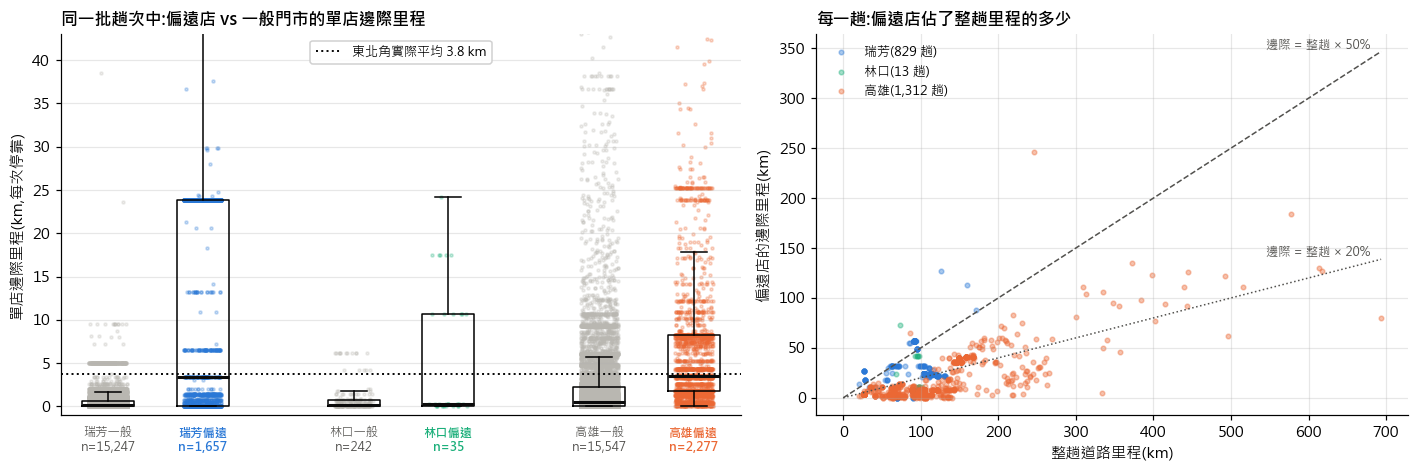

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
rng = np.random.default_rng(0)
data, labs = [], []
for i, nm in enumerate(DCS):
    l = LOO[(LOO["dc"] == nm) & (LOO["座標品質"] != "缺座標")]
    for j, (r, col) in enumerate([(False, "#b9b7b1"), (True, DCOL[nm])]):
        v = l.loc[l["偏遠受益型"] == r, "單店邊際 km"].clip(lower=0)
        x0 = i * 2.6 + j
        ax.scatter(x0 + rng.uniform(-0.2, 0.2, len(v)), v, s=4, alpha=0.25, color=col)
        ax.boxplot([v], positions=[x0], widths=0.55, showfliers=False, medianprops=dict(color="#0b0b0b", lw=2))
        ax.text(x0, -2.3, f"{nm}{'偏遠' if r else '一般'}\nn={len(v):,}", ha="center", va="top", fontsize=8,
                color=DCOL[nm] if r else "#52514e", fontweight="bold" if r else "normal")
ax.axhline(NE_ACTUAL, color="#0b0b0b", ls=":", lw=1.3, label=f"東北角實際平均 {NE_ACTUAL} km")
ax.set_xticks([]); ax.set_ylim(-1, 43); ax.set_ylabel("單店邊際里程(km,每次停靠)")
ax.legend(fontsize=8.5, loc="upper center", frameon=True, framealpha=0.9)
ax.set_title("同一批趟次中:偏遠店 vs 一般門市的單店邊際里程", loc="left", fontweight="bold", fontsize=11)

ax = axes[1]
for nm in DCS:
    d = M[OK & (M["dc"] == nm)]
    ax.scatter(d["整趟 km"], d["邊際 km"], s=9, alpha=0.4, color=DCOL[nm], label=f"{nm}({len(d):,} 趟)")
mx = M.loc[OK, "整趟 km"].max()
for f_, ls in [(0.5, "--"), (0.2, ":")]:
    ax.plot([0, mx], [0, mx * f_], color="#52514e", ls=ls, lw=1)
    ax.text(mx * 0.98, mx * f_, f"邊際 = 整趟 × {f_:.0%}", ha="right", va="bottom", fontsize=8, color="#52514e")
ax.set_xlabel("整趟道路里程(km)"); ax.set_ylabel("偏遠店的邊際里程(km)")
ax.legend(fontsize=8.5, frameon=False, loc="upper left")
ax.set_title("每一趟:偏遠店佔了整趟里程的多少", loc="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

In [13]:
# 每家偏遠門市:平均每次停靠多跑幾 km(只用座標品質可用的趟次)
st_m = (M[OK].assign(門市=M.loc[OK, "trip"].map(lambda t: "、".join(trips[t].loc[trips[t]["偏遠受益型"], "store"])))
        .groupby(["dc", "門市"]).agg(趟數=("trip", "size"), 每店邊際_km=("每家偏遠店邊際 km", "median"),
                                     邊際佔整趟=("邊際佔整趟", "median"), 主要任務=("任務", lambda s: s.mode().iat[0]),
                                     位置=("位置", lambda s: s.mode().iat[0])).reset_index())
st_m = st_m[st_m["趟數"] >= 5].sort_values("每店邊際_km", ascending=False)
print("同趟偏遠店組合(至少 5 趟),依每店邊際里程排序:")
st_m.head(25).style.hide(axis="index").format(precision=1).format({"邊際佔整趟": "{:.0%}"})

同趟偏遠店組合(至少 5 趟),依每店邊際里程排序:


dc,門市,趟數,每店邊際_km,邊際佔整趟,主要任務,位置
瑞芳,坪林順益店,459,23.893100,23%,05,後段
瑞芳,坪林順益店、平溪平安店,210,11.951000,21%,12,後段
瑞芳,新店龜山店、烏來烏萊店,22,11.078900,18%,05,後段
高雄,燕巢深水店,8,10.242400,16%,03,前段
高雄,麻豆黎明店、麻豆興民店、官田新田店、玉井民生店,91,8.942775,24%,04,中段
高雄,內埔水門店、三地門恆美店,5,8.850700,13%,03,中段
瑞芳,九份觀景店、金瓜石黃金店,19,8.703250,63%,05,前段
高雄,新化那拔店,295,8.227800,8%,04,中段
瑞芳,新店龜山店、烏來烏萊店、烏來溫泉店,11,7.774900,19%,12,後段
高雄,林邊中林店,18,7.455900,6%,04,後段


**判讀(第 6 節):**

- **順路,但不便宜。** 三個物流中心合計,每停靠一家偏遠受益型門市平均多跑 **9.5 km**(瑞芳 13.1、林口 10.7、高雄 6.9),約為東北角實測 3.8 km 的 2.5 倍。同一批趟次裡的一般門市,拿掉一家只少 0.2–0.5 km(中位數)。偏遠店不是專程送,但每一家都是全家路網上「最貴」的停靠點。
- **差異很大,集中在少數幾條「尾巴」:**
  - **坪林順益店**是最極端的例子:晚班 05 送完新店、文山後,最後再翻山到坪林,每趟為它多跑約 24 km;一年多來 459 趟都是這樣。
  - 烏來、新店山區(約 11 km)、高雄的麻豆—官田—玉井一串(約 9 km)、燕巢深水、三地門也偏高。
  - 高雄任務 04 的阿蓮、永安、萬丹、屏東沿海幾家店,剛好在幹線上,每店不到 2 km,和東北角的瑞芳區門市相似。
- **單店與整群的差別:** 左圖「偏遠店單店邊際」的中位數只有約 3.4 km,比整趟算法低。原因是偏遠店常**成群**出現,例如金山、萬里 6–8 家同一趟:只拿掉其中一家幾乎省不到,整群拿掉才看得出這段繞路(每店約 7 km)。共配要合併的正是「整群」,所以第 8 節用整趟算法。
- **只用精確座標的趟次**,每店 10.8 km,和含鄉鎮估計的 9.5 km 相近,鄉鎮估計沒有明顯拉偏結果。

## 7. 地圖:偏遠門市在路線上的位置

點的顏色 = 該店所在趟次的「每家偏遠店邊際里程」中位數(越紅越「繞」;用整趟算法,成群的偏遠店才不會被低估);灰點是同趟的一般門市;方塊是物流中心(高雄為反推位置)。只畫至少 5 趟可用趟次的門市。

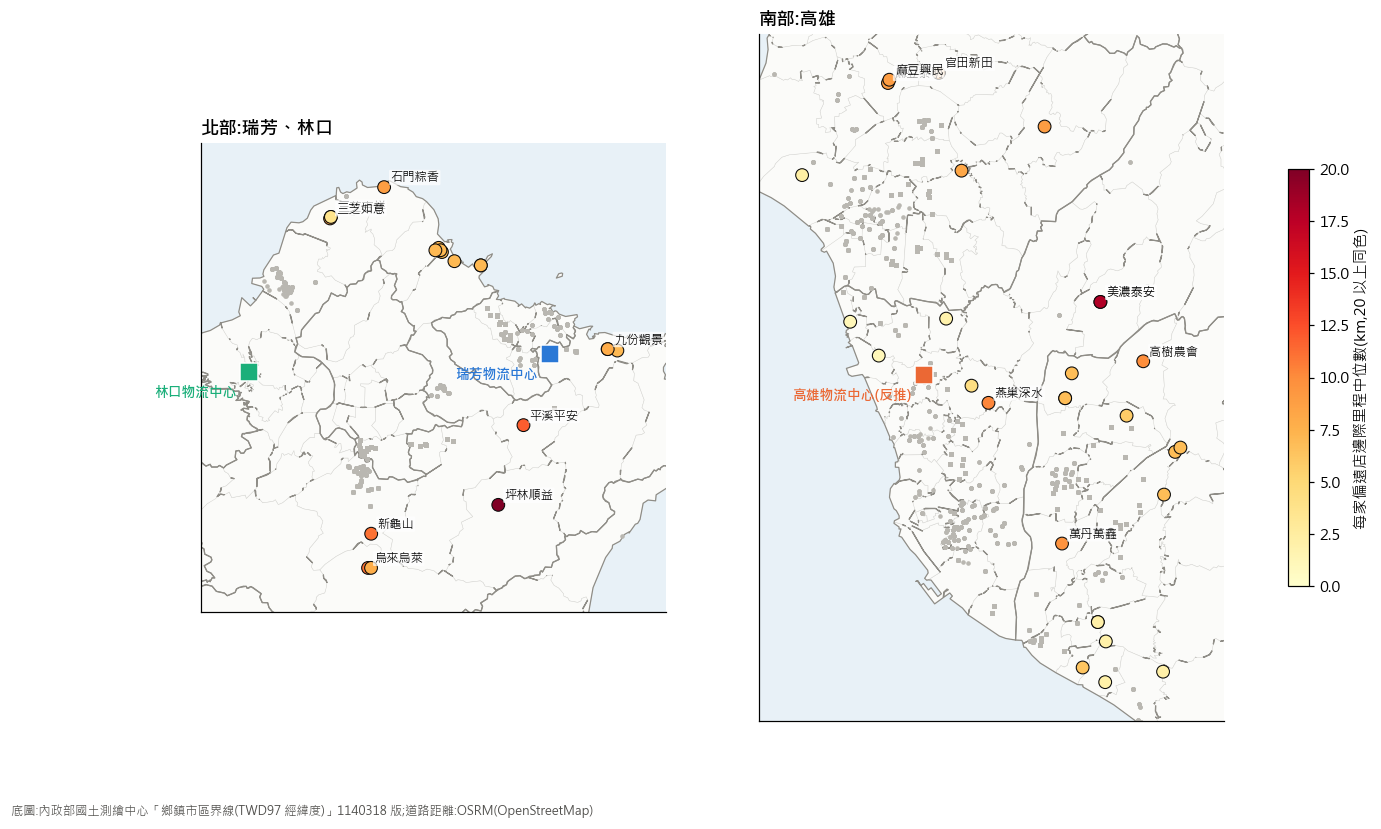

In [14]:
import matplotlib.colors as mcolors
from shapely.geometry import box
ps = [(t, sid) for t in M.loc[OK, "trip"] for sid in trips[t].loc[trips[t]["偏遠受益型"], "store_id"]]
med_loo = (pd.DataFrame(ps, columns=["trip", "store_id"]).merge(M[["trip", "dc", "每家偏遠店邊際 km"]], on="trip")
           .groupby(["dc", "store_id"])["每家偏遠店邊際 km"].agg(["median", "size"]).rename(columns={"median": "med"}).reset_index())
med_loo = med_loo[med_loo["size"] >= 5].merge(u[["dc", "store_id", "store", "lat", "lon"]], on=["dc", "store_id"])
norm_c = mcolors.Normalize(0, 20); cmap = plt.get_cmap("YlOrRd")
VIEWS = [("北部:瑞芳、林口", ["瑞芳", "林口"]), ("南部:高雄", ["高雄"])]
fig, axes = plt.subplots(1, 2, figsize=(15, 8.2))
for ax, (title, dcs) in zip(axes, VIEWS):
    pts = TR[TR["dc"].isin(dcs) & TR["精確"].fillna(False)]
    mm = med_loo[med_loo["dc"].isin(dcs)]
    bx = pd.concat([pts[["lat", "lon"]].quantile([0.01, 0.99]), mm[["lat", "lon"]],
                    pd.DataFrame([DC_XY[d] for d in dcs], columns=["lat", "lon"])])
    x0, x1 = bx["lon"].min() - 0.06, bx["lon"].max() + 0.06
    y0, y1 = bx["lat"].min() - 0.05, bx["lat"].max() + 0.05
    tw = TOWN[TOWN.intersects(box(x0, y0, x1, y1))].copy(); tw["geometry"] = tw.geometry.simplify(0.001)
    ax.set_facecolor("#e8f1f7")
    tw.plot(ax=ax, facecolor="#fbfbf9", edgecolor="#d6d5d1", linewidth=0.3)
    tw.dissolve(by="COUNTYNAME").boundary.plot(ax=ax, color="#8f8d87", linewidth=0.8)
    ax.scatter(pts["lon"], pts["lat"], s=4, color="#b9b7b1", zorder=2)
    sc = ax.scatter(mm["lon"], mm["lat"], c=mm["med"].clip(0, 20), cmap=cmap, norm=norm_c, s=70, edgecolor="#0b0b0b", linewidth=0.7, zorder=4)
    for _, r in mm.sort_values("med", ascending=False).head(8).iterrows():
        ax.annotate(r["store"].replace("店", ""), (r["lon"], r["lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7), zorder=5)
    for d in dcs:
        ax.scatter([DC_XY[d][1]], [DC_XY[d][0]], s=150, marker="s", color=DCOL[d], edgecolor="white", zorder=5)
        ax.annotate(f"{d}物流中心" + ("(反推)" if d == "高雄" else ""), (DC_XY[d][1], DC_XY[d][0]), xytext=(-8, -16), ha="right",
                    textcoords="offset points", fontsize=9, fontweight="bold", color=DCOL[d], zorder=6)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect(1 / math.cos(math.radians((y0 + y1) / 2)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title, loc="left", fontweight="bold")
fig.colorbar(sc, ax=axes, shrink=0.6, label="每家偏遠店邊際里程中位數(km,20 以上同色)")
fig.text(0.01, 0.01, "底圖:內政部國土測繪中心「鄉鎮市區界線(TWD97 經緯度)」1140318 版;道路距離:OSRM(OpenStreetMap)", fontsize=8, color="#52514e")
plt.show()

## 8. 對 `3_remote_scan` 放大估算的影響

`3_remote_scan` 第 4 節的每店效益(每輪少跑 0.45 / 5.77 / 8.65 km)全部來自東北角,而且假設每日一輪。這裡改用三個物流中心的實測值:

**每家偏遠門市每次停靠的共配節省 = 全家實測邊際里程 × 共配可省下的比例**

共配可省下的比例取自 `2_a_group_rebuild` 第 7 節校準版(每趟上限 25 店)的東北角結果:
- **專程型**(貢寮、雙溪,沒有順路幹線):四品牌邊際里程 136.1 → 66.9 km,省 **51%**。
- **順路型**(瑞芳區、平溪,插在既有幹線上):71.0 → 65.2 km,省 **8%**。

實測的每一趟依**每家偏遠店的邊際里程**分成兩型。東北角校準版中,順路型門市每店約 2.8 km、專程型每店約 17 km,取兩者的幾何平均(約 7 km)當分界:**每店 ≥ 7 km 視為專程型**(車子為了它繞了一大段),其餘為順路型。第 4 節已看到幾乎沒有「整趟只為偏遠店出車」的情形,所以不用「佔整趟比例」來分。
- **低估:** 全部用順路型比例 8%。
- **中估:** 依每趟實際型態分別套用 51% 或 8%。
- **高估:** 全部用專程型比例 51%。

年化用實測的**每家偏遠店每個有送日的停靠次數**,取代「每日一輪」。全臺門市數沿用 `3_remote_scan` 的 717 家(四品牌)。

In [15]:
CAL = json.load(open(P("poc", "cache", "rebuild_calibrated.json"), encoding="utf-8"))["25"]
A_rem = sum(CAL[b]["remote"]["km"] for b in BRANDS); B_rem = CAL["B"]["remote"]["km"]
A_on = sum(CAL[b][z]["km"] for b in BRANDS for z in ["05", "12"]); B_on = sum(CAL["B"][z]["km"] for z in ["05", "12"])
S_DED, S_ON = 1 - B_rem / A_rem, 1 - B_on / A_on
ver = pd.read_csv(P("poc", "data", "ne_stores_verified.csv"), encoding="utf-8-sig")
ver = ver[ver["include"] == 1]
n_ded, n_on = int(ver["district"].isin(["貢寮區", "雙溪區"]).sum()), int(ver["district"].isin(["瑞芳區", "平溪區"]).sum())
CUT = math.sqrt(A_rem / n_ded * A_on / n_on)
print(f"校準版(上限 25 店):專程型 {n_ded} 店省 {S_DED:.0%}({A_rem:.1f} → {B_rem:.1f} km,每店 {A_rem / n_ded:.1f} km)、"
      f"順路型 {n_on} 店省 {S_ON:.0%}({A_on:.1f} → {B_on:.1f} km,每店 {A_on / n_on:.1f} km)→ 分界 {CUT:.1f} km/店")

MO = M[OK].copy()
MO["型態"] = np.where(MO["每家偏遠店邊際 km"] >= CUT, "專程型", "順路型")
print("偏遠店停靠中屬於專程型的比例:", (MO.assign(w=MO["偏遠店數"] * (MO["型態"] == "專程型")).groupby("dc")["w"].sum()
                                  / MO.groupby("dc")["偏遠店數"].sum()).reindex(DCS).round(2).to_dict())
print("實測趟次型態:", MO.groupby("dc")["型態"].value_counts(normalize=True).unstack().reindex(DCS).round(2).to_dict("index"))
per_visit = {"低估(全部順路型)": MO["邊際 km"].sum() * S_ON / MO["偏遠店數"].sum(),
             "中估(依實際型態)": (MO["邊際 km"] * np.where(MO["型態"] == "專程型", S_DED, S_ON)).sum() / MO["偏遠店數"].sum(),
             "高估(全部專程型)": MO["邊際 km"].sum() * S_DED / MO["偏遠店數"].sum()}
freq = rs.loc[rs["有送的天數"] >= 30, "每個有送日幾次"].median()
print(f"每家偏遠店每個有送日的停靠次數(中位數,只計有送 30 天以上的門市):{freq:.2f}")

KG_PER_KM = 0.212 * 2.60
N_TW = int(s4["偏遠受益型"].sum())
OLD = {"低估(全部順路型)": (0.45, 64.4), "中估(依實際型態)": (5.77, 832.2), "高估(全部專程型)": (8.65, 1247.8)}
new = pd.DataFrame([{"情境": k, "3_remote_scan:每店每輪 km": OLD[k][0], "3_remote_scan:每年公噸(每日一輪)": OLD[k][1],
                     "實測:每店每次停靠 km": v, "實測:每年公噸(每日一輪)": N_TW * v * 365 * KG_PER_KM / 1000,
                     f"實測:每年公噸(每日 {freq:.1f} 次)": N_TW * v * freq * 365 * KG_PER_KM / 1000} for k, v in per_visit.items()])
new.style.hide(axis="index").format(precision=1).format({c: "{:,.0f}" for c in new.columns if "公噸" in c})

校準版(上限 25 店):專程型 8 店省 51%(136.1 → 66.9 km,每店 17.0 km)、順路型 25 店省 8%(71.0 → 65.3 km,每店 2.8 km)→ 分界 7.0 km/店
偏遠店停靠中屬於專程型的比例: {'瑞芳': 0.84, '林口': 0.49, '高雄': 0.46}
實測趟次型態: {'瑞芳': {'專程型': 0.94, '順路型': 0.06}, '林口': {'專程型': 0.54, '順路型': 0.46}, '高雄': {'專程型': 0.38, '順路型': 0.62}}
每家偏遠店每個有送日的停靠次數(中位數,只計有送 30 天以上的門市):1.02


情境,3_remote_scan:每店每輪 km,3_remote_scan:每年公噸(每日一輪),實測:每店每次停靠 km,實測:每年公噸(每日一輪),實測:每年公噸(每日 1.0 次)
低估(全部順路型),0.450000,64,0.772445,111,114
中估(依實際型態),5.770000,832,4.190580,604,618
高估(全部專程型),8.650000,"1,248",4.828480,697,712


**判讀(第 8 節):**

- 每家偏遠門市每次停靠的共配節省:中估 **4.2 km**(低 0.8、高 4.8),`3_remote_scan` 原本是 5.77 km(低 0.45、高 8.65)。
- 放大到全臺 717 家,每年約 **600 公噸 CO₂**(110–700),比 `3_remote_scan` 的 830 公噸(64–1,250)低約 3 成,**範圍也明顯變窄**:原本高估情境假設每家都像貢寮一樣專程,實測沒有這種情形;低估情境原本把每店壓到 0.45 km,實測偏遠店的邊際里程不可能這麼低。
- 中估接近高估,是因為瑞芳 84%、高雄 46% 的偏遠店停靠每店多跑 7 km 以上,屬於「繞一大段」的專程型。
- 實測每天一次,所以年化結果和「每日一輪」幾乎相同。
- 和方案 B(物流中心改插電,全臺示意 470–730 公噸)相比,**仍在同一數量級**。`3_remote_scan` 第 6 節的結論不變,數字要改。

## 9. 結論

_(以下依本次執行結果撰寫;更改門檻、重抓 OSM 或重查 OSRM 後請一併檢查數字。)_

### 主要發現

1. **東北角的「順路、不專程」在三個物流中心都成立。** 瑞芳、林口、高雄的配送計畫中共有 67 家偏遠受益型全家門市,出現在 2,700 多趟裡,沒有一趟是只為偏遠店出車:偏遠店一律和 6–24 家一般門市同趟,過半的趟次只有 0–3%。瑞芳把它們排在趟次的最後(坪林、烏來、平溪),高雄多排在前段、中段(出岡山先送阿蓮、燕巢、屏東)。
2. **但順路不等於便宜。** 每停一家偏遠店平均多跑 **9.5 km**,是東北角實測 3.8 km 的 2.5 倍,也是同趟一般門市(0.2–0.5 km)的 20 倍以上。東北角的 3.8 km 剛好落在偏低的一端:瑞芳區門市就在晚班幹線的起點附近。其他地方的偏遠店,常要在幹線尾端再繞 10–25 km(坪林每趟約 24 km)。
3. **偏遠店常成群出現,共配要看「整群」。** 金山萬里、麻豆官田玉井、里港鹽埔內埔等地,同一趟有 3–8 家偏遠店。單拿一家幾乎省不到,整群的繞路才是共配可以分攤的部分。
4. **放大估算下修約 3 成,範圍變窄。** 用實測邊際里程,乘上東北角校準版的共配節省比例(專程型 51%、順路型 8%),全臺 717 家偏遠受益型門市每年約可減 **600 公噸 CO₂(110–700)**。`3_remote_scan` 原本是 830(64–1,250)。仍和方案 B(470–730)同一數量級。
5. **「每日一輪」的假設有資料支持。** 常態配送的偏遠店,有送的日子幾乎都是一天一次。

### 對報告的影響

- `3_remote_scan` 第 6 節「共配每年約 830 公噸」建議改為**約 600 公噸(110–700),依三個物流中心實際路線校正**,並說明這是用全家的路線推估四個品牌。
- 研究結論可以從「共配效益集中在偏遠門市」再推進一步:**效益集中在幹線尾端的偏遠「門市群」**,例如坪林、烏來、北海岸、麻豆—玉井、屏東山腳。這些地方才值得優先試辦,不必從全臺 717 家同時開始。
- 東北角(貢寮、雙溪)仍然是好的示範場域,但它的 3.8 km 不能代表全臺偏遠門市,報告中要避免直接引用成全臺平均。

### 限制

1. **只有全家的路線:** 他牌的邊際里程無法觀察。OK、萊爾富的門市更稀疏,實際繞路可能更長,所以用全家推估四品牌偏保守。
2. **只涵蓋三個物流中心:** 全臺 215 家偏遠受益型全家門市只驗證了 62 家;雲林、嘉義、南投、花蓮、宜蘭等地完全沒有資料。
3. **高雄的座標不完整:** 高雄門市不在門市主檔,約 30% 的含偏遠店趟次因前後站沒有座標而排除,另有部分用鄉鎮估計座標;高雄物流中心的位置也是反推的,誤差可能有數公里。有 19 家偏遠店完全沒有可用趟次,其中常態配送的是**林園 5 家**(各約 53 次)與**獅子金流店**(50 次),其餘是臺東等只出現 1–7 次的門市。
4. **共配節省比例只來自東北角:** 51% 與 8% 都來自同一個案例,而且「每店 7 km」的分界是人為選定的;低、高估情境就是為了涵蓋這個不確定性。
5. **道路距離:** OSRM 的最快路線經過最短路徑修正,但沒有考慮實際路況、禁行與車型限制;時間窗、溫層與貨量仍未納入。

### 下一步

1. 向助教或業者確認**雲林、嘉義、南投、花蓮**等偏遠門市由哪個物流中心配送,能否取得該場站的配送計畫。
2. 以坪林、北海岸、麻豆—玉井這幾個「門市群」為對象,用 `2_a_group_rebuild` 第 7 節的校準版方法,直接重算四品牌的 A/B 比較,取代第 8 節借用東北角比例的作法。
3. 高雄門市座標可再用全家官網門市查詢或地址地理編碼補齊,提高高雄趟次的可用率。